<a href="https://colab.research.google.com/github/krishu-shrestha/Gradient-Descent-Implementations/blob/main/dcs_410_week4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment: Understanding and Implementing Gradient Descent

### Objectives
- **Part 1: Practical Implementation of Gradient Descent:** Manually optimize a quadratic function, analyze the impact of different learning rates on convergence and stability, and visualize the optimization paths using contour and 3D plots.
- **Part 2: Normalization Techniques in a Small Neural Network:** Build feedforward neural networks using TensorFlow/Keras to compare no internal normalization, Batch Normalization, and Layer Normalization on a synthetic binary classification dataset.

## 1. Required Library Imports and Reproducibility Settings

In this section, we import the necessary libraries and set the global seeds for Python, NumPy, and TensorFlow to ensure reproducibility of our experiments.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import tensorflow as tf
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configure Plotting Aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

## Part 1: Practical Implementation of Gradient Descent

### 2. Mathematical Definition of the Quadratic Function and its Gradient

We define the quadratic objective function $f(x, y) = x^2 + 4y^2$.

#### Analytical Gradient Derivation
The gradient is the vector of partial derivatives with respect to each independent variable:

$$\nabla f(x, y) = \begin{bmatrix} \frac{\partial f}{\partial x} \\ \frac{\partial f}{\partial y} \end{bmatrix} = \begin{bmatrix} 2x \\ 8y \end{bmatrix}$$

#### Convergence Properties and Step-Size Bounds
For a quadratic objective function $f(\mathbf{w}) = \frac{1}{2}\mathbf{w}^T \mathbf{H}\mathbf{w}$, gradient descent converges if the learning rate $\eta$ satisfies:
$$0 < \eta < \frac{2}{\lambda_{\max}(\mathbf{H})}$$
where $\lambda_{\max}(\mathbf{H})$ is the maximum eigenvalue of the Hessian matrix $\mathbf{H}$.

Our function can be written as:
$$f(x, y) = \frac{1}{2} \begin{bmatrix} x & y \end{bmatrix} \begin{bmatrix} 2 & 0 \\ 0 & 8 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix}$$
The Hessian matrix is:
$$\mathbf{H} = \begin{bmatrix} 2 & 0 \\ 0 & 8 \end{bmatrix}$$

The eigenvalues are $\lambda_1 = 2$ and $\lambda_2 = 8$. Thus, $\lambda_{\max}(\mathbf{H}) = 8$.

The theoretical upper limit for stability is:
$$\eta_{\text{crit}} = \frac{2}{8} = 0.25$$
- For $\eta < 0.25$, gradient descent converges.
- For $\eta = 0.25$, we expect persistent oscillation in the $y$-dimension.
- For $\eta > 0.25$, gradient descent diverges due to overshooting along the steeper $y$-axis.

In [2]:
def f(x, y):
    """Quadratic objective function."""
    return x**2 + 4*(y**2)

def grad_f(x, y):
    """Analytical gradient vector."""
    return np.array([2*x, 8*y], dtype=np.float64)

### 3. Gradient Descent Implementation From Scratch

We implement standard Gradient Descent with divergence protection.

In [3]:
def gradient_descent(start_point, lr, max_iters=100, tolerance=1e-8, max_val=1e10):
    x, y = float(start_point[0]), float(start_point[1])
    history = [(x, y, f(x, y))]
    diverged = False

    for i in range(max_iters):
        grad = grad_f(x, y)

        # Gradient update step
        x_next = x - lr * grad[0]
        y_next = y - lr * grad[1]

        # Divergence / Overflow checks
        if (not np.isfinite(x_next) or not np.isfinite(y_next) or
            abs(x_next) > max_val or abs(y_next) > max_val):
            diverged = True
            break

        loss_next = f(x_next, y_next)
        history.append((x_next, y_next, loss_next))

        # Convergence condition
        if np.sqrt((x_next - x)**2 + (y_next - y)**2) < tolerance:
            break

        x, y = x_next, y_next

    return np.array(history), diverged

### 4. Learning-Rate Experiments & Results Table

In [4]:
start_point = (4.0, 3.0)
learning_rates = [0.01, 0.1, 0.25, 0.3]
results = {}

for lr in learning_rates:
    history, diverged = gradient_descent(start_point, lr=lr, max_iters=150)
    results[lr] = {
        'history': history,
        'diverged': diverged
    }

summary_data = []
for lr, res in results.items():
    hist = res['history']
    final_pt = hist[-1][:2] if not res['diverged'] else (np.nan, np.nan)
    final_loss = hist[-1][2] if not res['diverged'] else np.nan
    iters = len(hist) - 1

    summary_data.append({
        'Learning Rate': lr,
        'Iterations': iters,
        'Final Point (x, y)': f"({final_pt[0]:.4f}, {final_pt[1]:.4f})" if not res['diverged'] else "Diverged",
        'Final Loss': f"{final_loss:.2e}" if not res['diverged'] else "Inf / NaN",
        'Status': "Diverged" if res['diverged'] else "Converged"
    })

df_results = pd.DataFrame(summary_data)
display(df_results)

,Learning Rate,Iterations,"Final Point (x, y)",Final Loss,Status
0,0.01,150,"(0.1932, 0.0000)",3.73e-02,Converged
1,0.10,83,"(0.0000, 0.0000)",1.31e-15,Converged
2,0.25,150,"(0.0000, 3.0000)",3.60e+01,Converged
3,0.30,65,Diverged,Inf / NaN,Diverged


### 5. Convergence Plots and Interpretation

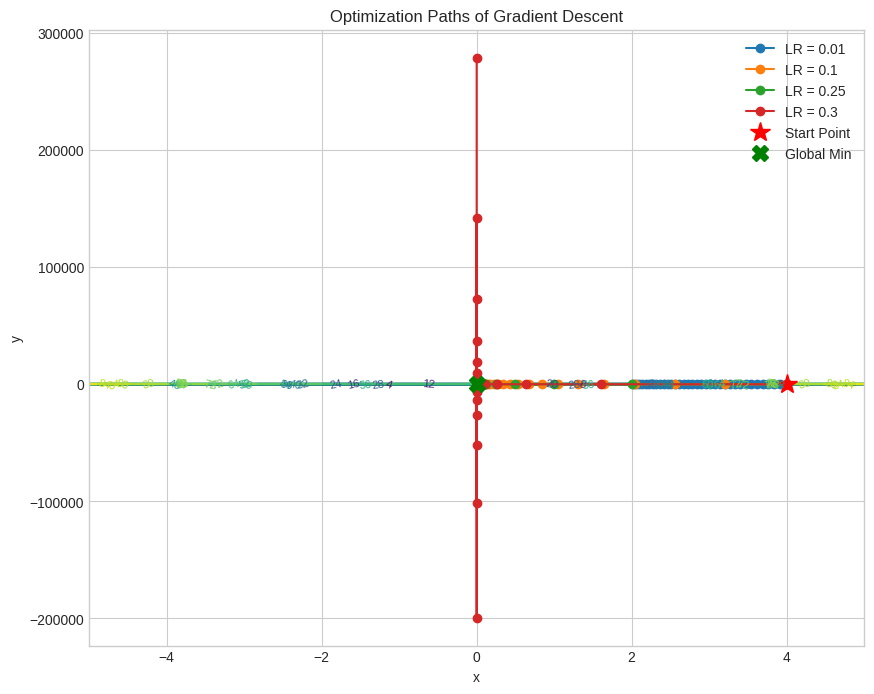

In [5]:
# Visualization 1: Contour Plot & Optimization Paths
fig, ax = plt.subplots(figsize=(10, 8))

x_val = np.linspace(-5.0, 5.0, 400)
y_val = np.linspace(-4.0, 4.0, 400)
X, Y = np.meshgrid(x_val, y_val)
Z = f(X, Y)

contour = ax.contour(X, Y, Z, levels=25, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)

for lr, res in results.items():
    hist = res['history']
    # Plot path up to a limit for cleaner visualization of divergent paths
    plot_len = min(len(hist), 35)
    ax.plot(hist[:plot_len, 0], hist[:plot_len, 1], '-o', label=f'LR = {lr}')

ax.plot(start_point[0], start_point[1], 'r*', markersize=15, label='Start Point')
ax.plot(0, 0, 'gX', markersize=12, label='Global Min')
ax.set_title('Optimization Paths of Gradient Descent')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()
plt.show()

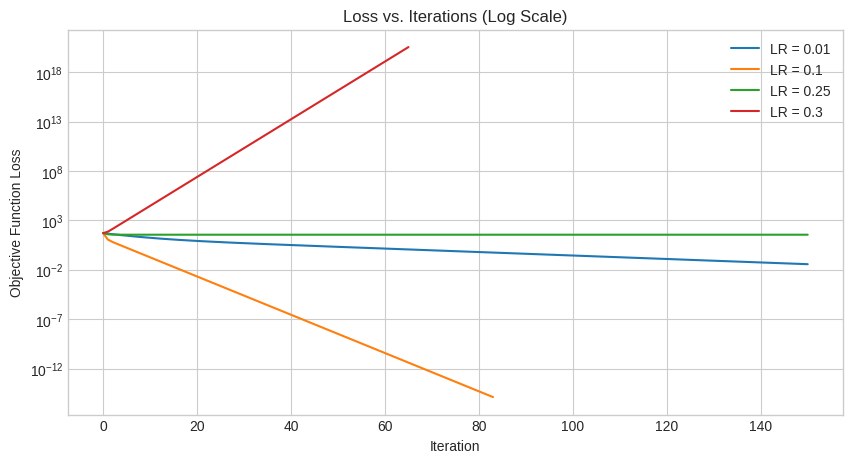

In [6]:
# Visualization 2: Loss versus Iteration (Logarithmic Scale)
fig, ax = plt.subplots(figsize=(10, 5))
for lr, res in results.items():
    hist = res['history']
    losses = hist[:, 2]
    # Clip loss values below a tiny value to prevent log(0) issues
    losses_clipped = np.clip(losses, 1e-15, None)
    ax.plot(losses_clipped, label=f'LR = {lr}')

ax.set_yscale('log')
ax.set_title('Loss vs. Iterations (Log Scale)')
ax.set_xlabel('Iteration')
ax.set_ylabel('Objective Function Loss')
ax.legend()
plt.show()

#### Part 1 Discussion & Interpretation
- **LR = 0.01**: Slow, stable convergence. It safely converges to $(0,0)$ but takes many iterations because the step size is small.
- **LR = 0.1**: Optimal convergence speed. It converges rapidly to the minimum without significant oscillations.
- **LR = 0.25**: Boundary stability condition ($\eta = \frac{2}{\lambda_{\max}}$). While $x$ converges towards $0$, $y$ oscillates indefinitely between $3$ and $-3$, yielding stable bounding loops.
- **LR = 0.3**: Diverges rapidly. The learning rate exceeds the theoretical boundary $\eta_{\text{crit}} = 0.25$, causing overshooting along the steeper $y$-dimension.

## Part 2: Normalization Techniques in a Small Neural Network

### 6. Dataset Generation, Train-Validation-Test Split, and Preprocessing

In [7]:
# Generate synthetic dataset
X, y = make_moons(n_samples=1500, noise=0.3, random_state=SEED)

# Split into Train (80%) and Test (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Further split Train into Train and Validation (15% of the total dataset)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1875, random_state=SEED, stratify=y_train_full
)

# Feature Standardization using StandardScaler (fit ONLY on training set)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(f"Train samples: {X_train.shape[0]}, Val samples: {X_val.shape[0]}, Test samples: {X_test.shape[0]}")

Train samples: 975, Val samples: 225, Test samples: 300


### 7. Neural-Network Model Definitions

In [8]:
def create_model(normalization_type=None):
    """
    Factory function to compile comparable feedforward networks.
    normalization_type can be: None, 'batch', or 'layer'
    """
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(2,)))

    # Hidden Layer 1
    model.add(tf.keras.layers.Dense(64, use_bias=True))
    if normalization_type == 'batch':
        model.add(tf.keras.layers.BatchNormalization())
    elif normalization_type == 'layer':
        model.add(tf.keras.layers.LayerNormalization())
    model.add(tf.keras.layers.Activation('relu'))

    # Hidden Layer 2
    model.add(tf.keras.layers.Dense(32, use_bias=True))
    if normalization_type == 'batch':
        model.add(tf.keras.layers.BatchNormalization())
    elif normalization_type == 'layer':
        model.add(tf.keras.layers.LayerNormalization())
    model.add(tf.keras.layers.Activation('relu'))

    # Output Layer
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    # SGD Optimizer with static learning rate
    optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

### 8. Training the Three Models

In [9]:
EPOCHS = 60
BATCH_SIZE = 32

# Set random seeds before compiling and training each model
tf.random.set_seed(SEED)
model_no_norm = create_model(normalization_type=None)
hist_no_norm = model_no_norm.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
)

tf.random.set_seed(SEED)
model_batch_norm = create_model(normalization_type='batch')
hist_batch_norm = model_batch_norm.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
)

tf.random.set_seed(SEED)
model_layer_norm = create_model(normalization_type='layer')
hist_layer_norm = model_layer_norm.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
)

print("Training completed successfully.")

Training completed successfully.


### 9. Results Table and Convergence Comparison

We define a convergence speed metric: **The first epoch at which the validation loss reaches its absolute minimum.**

In [10]:
models_dict = {
    'No Norm': (model_no_norm, hist_no_norm),
    'Batch Norm': (model_batch_norm, hist_batch_norm),
    'Layer Norm': (model_layer_norm, hist_layer_norm)
}

comparison_rows = []

for name, (model, hist) in models_dict.items():
    train_loss = hist.history['loss'][-1]
    val_loss = hist.history['val_loss'][-1]

    # Evaluate on held-out test set
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    # Compute Convergence Speed metric
    best_epoch = np.argmin(hist.history['val_loss']) + 1 # 1-indexed epoch

    comparison_rows.append({
        'Model': name,
        'Final Train Loss': f"{train_loss:.4f}",
        'Final Val Loss': f"{val_loss:.4f}",
        'Test Loss': f"{test_loss:.4f}",
        'Test Accuracy': f"{test_acc * 100:.2f}%",
        'Epoch of Min Val Loss': best_epoch
    })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

,Model,Final Train Loss,Final Val Loss,Test Loss,Test Accuracy,Epoch of Min Val Loss
0,No Norm,0.2987,0.3096,0.3117,87.00%,60
1,Batch Norm,0.2371,0.2513,0.2353,90.67%,58
2,Layer Norm,0.1840,0.2784,0.2339,89.33%,22


### 10. Visualization of Training and Validation Metrics

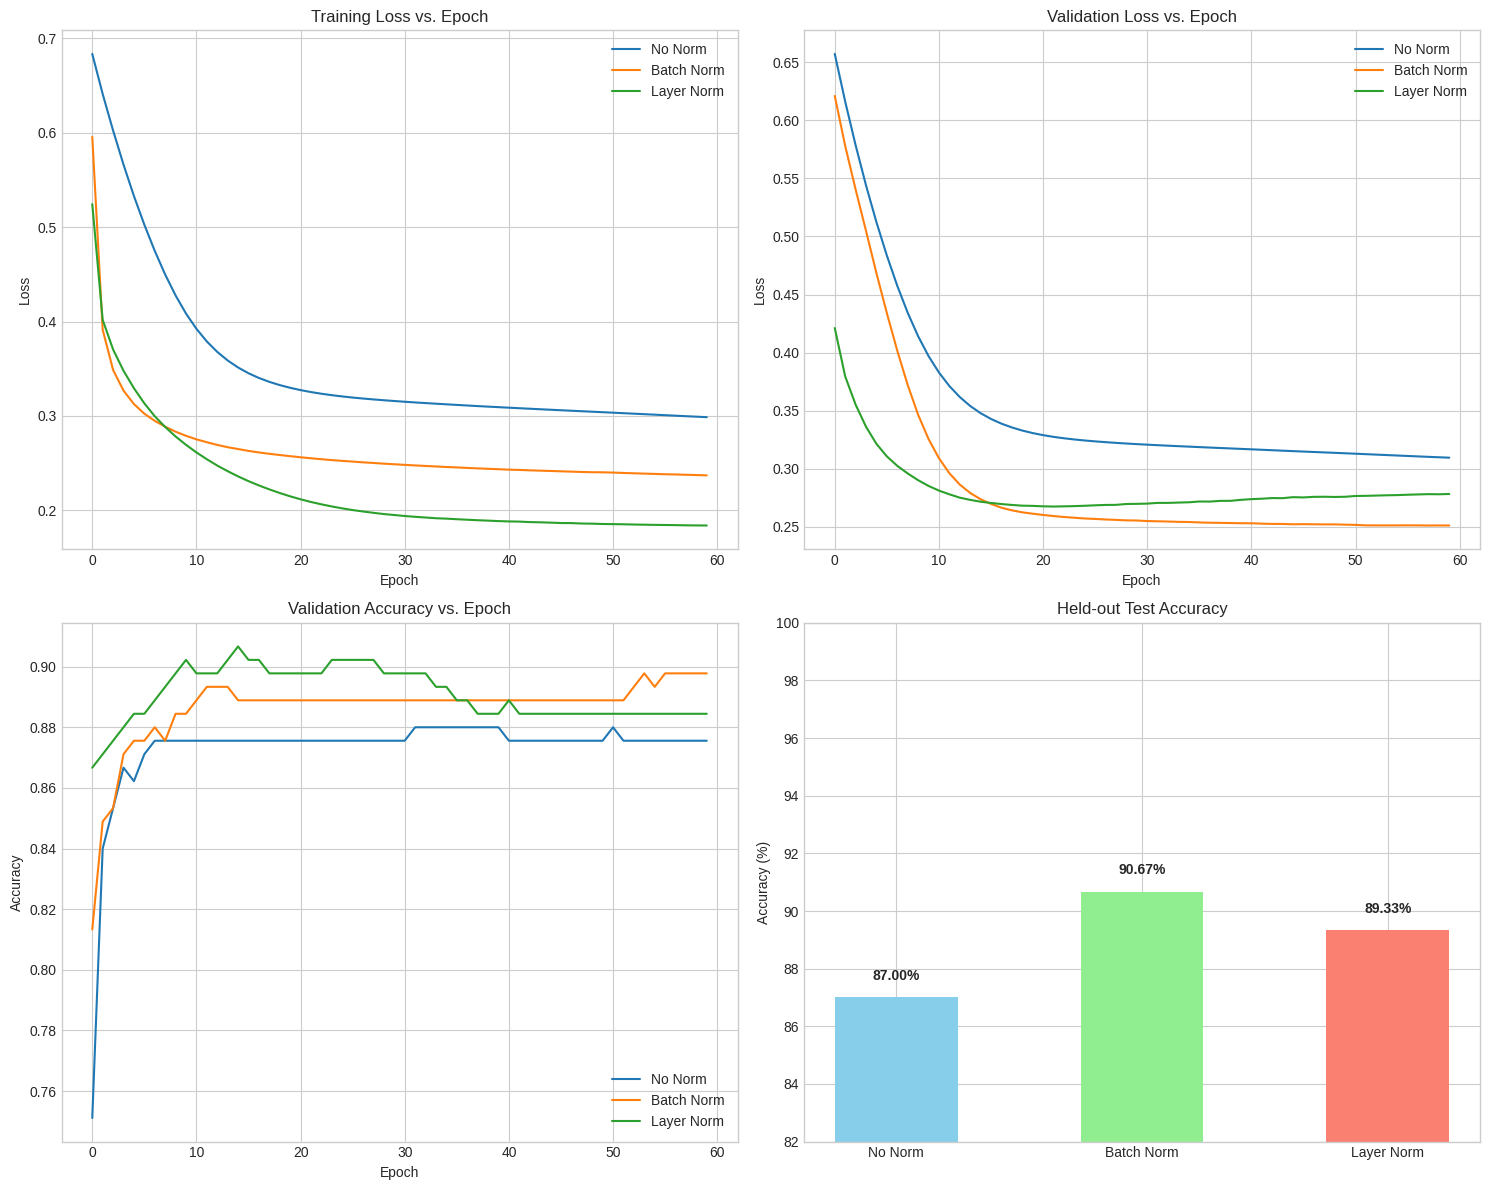

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12))

# 1. Training Loss
axs[0, 0].plot(hist_no_norm.history['loss'], label='No Norm')
axs[0, 0].plot(hist_batch_norm.history['loss'], label='Batch Norm')
axs[0, 0].plot(hist_layer_norm.history['loss'], label='Layer Norm')
axs[0, 0].set_title('Training Loss vs. Epoch')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

# 2. Validation Loss
axs[0, 1].plot(hist_no_norm.history['val_loss'], label='No Norm')
axs[0, 1].plot(hist_batch_norm.history['val_loss'], label='Batch Norm')
axs[0, 1].plot(hist_layer_norm.history['val_loss'], label='Layer Norm')
axs[0, 1].set_title('Validation Loss vs. Epoch')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Loss')
axs[0, 1].legend()

# 3. Validation Accuracy
axs[1, 0].plot(hist_no_norm.history['val_accuracy'], label='No Norm')
axs[1, 0].plot(hist_batch_norm.history['val_accuracy'], label='Batch Norm')
axs[1, 0].plot(hist_layer_norm.history['val_accuracy'], label='Layer Norm')
axs[1, 0].set_title('Validation Accuracy vs. Epoch')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('Accuracy')
axs[1, 0].legend()

# 4. Bar Chart comparing Test Accuracy
names = [row['Model'] for row in comparison_rows]
accuracies = [float(row['Test Accuracy'].replace('%','')) for row in comparison_rows]
bars = axs[1, 1].bar(names, accuracies, color=['skyblue', 'lightgreen', 'salmon'], width=0.5)
axs[1, 1].set_title('Held-out Test Accuracy')
axs[1, 1].set_ylabel('Accuracy (%)')
axs[1, 1].set_ylim(min(accuracies) - 5, 100)
for bar in bars:
    yval = bar.get_height()
    axs[1, 1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Overall Comparison, Limitations, and Conclusions

### General Findings
- **Part 1 (Mathematical Optimization):** Proved how the maximum eigenvalue ($\lambda_{\max}$) of a quadratic function defines the maximum stable learning rate threshold ($0.25$). Any step size above this boundary causes numerical instability and immediate divergence.
- **Part 2 (Deep Learning Normalization):**
  - Both **Batch Normalization** and **Layer Normalization** reshape distributions to prevent gradients from exploding/vanishing. Batch Norm scales values across mini-batches, which provides training stability, while Layer Norm standardizes across individual layers.
  - On small networks and low-dimensional datasets (such as `make_moons`), internal normalization can sometimes act as a slight regularizer, although its benefits are most striking in complex, deep neural architectures where gradient propagation is otherwise difficult.
  
### Limitations
1. Synthetic low-dimensional datasets like `make_moons` do not suffer from severe covariate shifts or deep internal issues. Consequently, basic gradient descent can sometimes perform comparably well to standardized setups.
2. In tiny batch settings, batch normalization results can fluctuate due to noisy sample-variance approximations.

In [1]:
!git clone https://github.com/krishu-shrestha/Gradient-Descent-Implementations.git

Cloning into 'Gradient-Descent-Implementations'...


In [2]:
!cp "/content/dcs 410 week4.ipynb" "/content/Gradient-Descent-Implementations/"

cp: cannot stat '/content/dcs 410 week4.ipynb': No such file or directory
